In [3]:
pip install yfinance pandas numpy matplotlib

  Using cached beautifulsoup4-4.15.0-py3-none-any.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pillow-12.3.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (9.1 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 10.8 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 14.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 13.6 MB/s  0:00:00 eta 0:00:01
Using cached beautifulsoup4-4.15.0-py3-none-any.whl (109 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 15.2 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 15.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 15.7 MB/s  0:00:00 eta 0:00:01
Using cached pillow-12.3.0-cp314-cp314-macosx_11_0_arm64.whl (4.8 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19/19 [matplotlib]9 [matplotlib]up4]
Note: you may need to res

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

In [8]:
tickers = ["GC=F", "SI=F", "CL=F", "BTC-USD"]
prices = yf.download(tickers, start="2015-01-01")["Close"]
prices.columns = ["bitcoin", "oil", "gold", "silver"]
prices.tail()

[*********************100%***********************]  4 of 4 completed


,bitcoin,oil,gold,silver
Date,,,,
2026-09-29,83622.429688,89.379997,4179.700195,60.667999
2026-09-30,83553.851562,90.419998,4186.700195,60.098000
2026-10-01,84853.101562,92.870003,4202.299805,60.724998
2026-10-02,84497.210938,91.110001,4162.299805,59.977001
2026-10-03,84749.570312,NaN,NaN,NaN


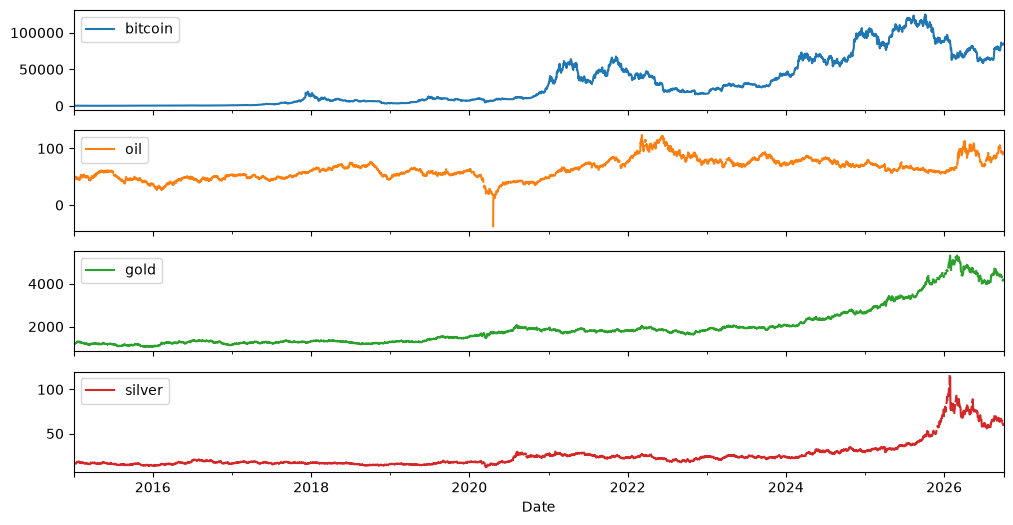

In [9]:
prices.plot(subplots=True, figsize=(12, 6))
plt.show()

In [14]:
prices.loc["2020-01-01":"2020-2-29"]

,bitcoin,oil,gold,silver
Date,,,,
2020-01-01,7200.174316,NaN,NaN,NaN
2020-01-02,6985.470215,61.180000,1524.500000,17.966000
2020-01-03,7344.884277,63.049999,1549.199951,18.068001
2020-01-04,7410.656738,NaN,NaN,NaN
2020-01-05,7411.317383,NaN,NaN,NaN
2020-01-06,7769.219238,63.270000,1566.199951,18.097000
2020-01-07,8163.692383,62.700001,1571.800049,18.316000
2020-01-08,8079.862793,59.610001,1557.400024,18.087999
2020-01-09,7879.071289,59.560001,1551.699951,17.860001


In [15]:
prices.isna().sum()

bitcoin       0
oil        1339
gold       1339
silver     1340
dtype: int64

In [16]:
prices[(prices <= 0).any(axis=1)]

,bitcoin,oil,gold,silver
Date,,,,
2020-04-20,6881.958496,-37.630001,1701.599976,15.556


In [17]:
prices = prices.dropna()
prices = prices[prices > 0].ffill()
len(prices)

2954

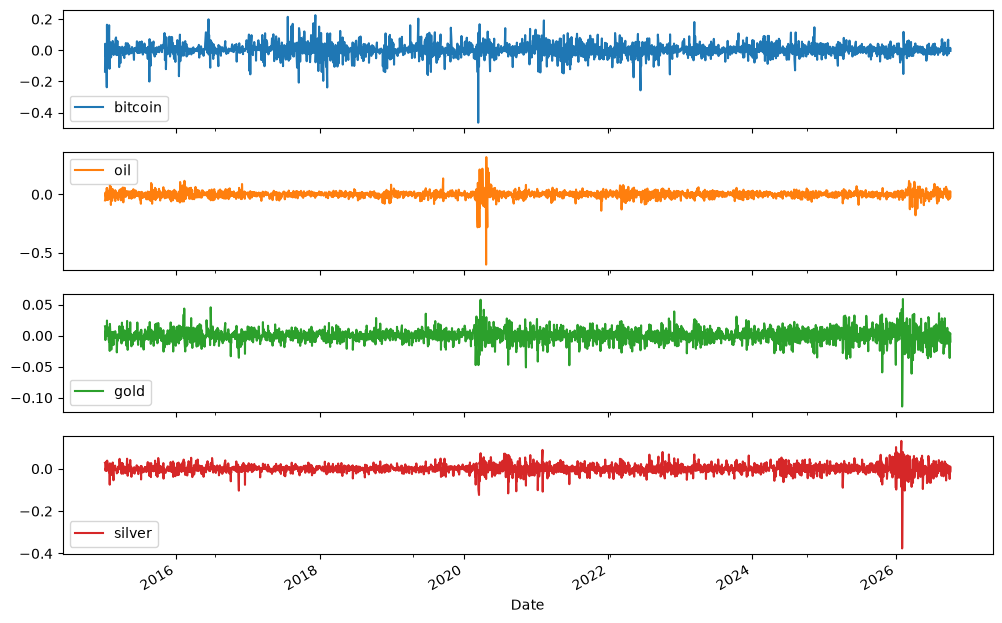

In [18]:
returns = np.log(prices).diff().dropna()
returns.plot(subplots=True, figsize=(12, 8))
plt.show()

In [19]:
returns.std() * np.sqrt(252)


bitcoin    0.660102
oil        0.497307
gold       0.168180
silver     0.340568
dtype: float64

In [20]:
returns.corr()

,bitcoin,oil,gold,silver
bitcoin,1.000000,0.040393,0.092085,0.114036
oil,0.040393,1.000000,0.059868,0.114397
gold,0.092085,0.059868,1.000000,0.772240
silver,0.114036,0.114397,0.772240,1.000000


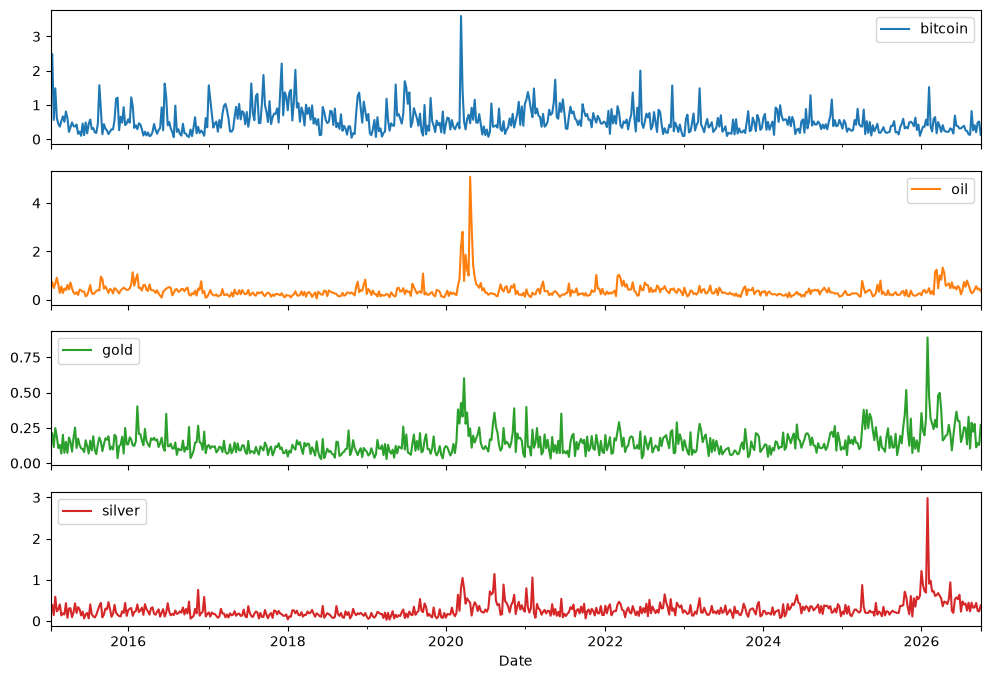

In [21]:
rv = np.sqrt((returns**2).resample("W-FRI").sum()) * np.sqrt(52)
rv = rv[returns["gold"].resample("W-FRI").count() >= 3]
rv.plot(subplots=True, figsize=(12, 8))
plt.show()

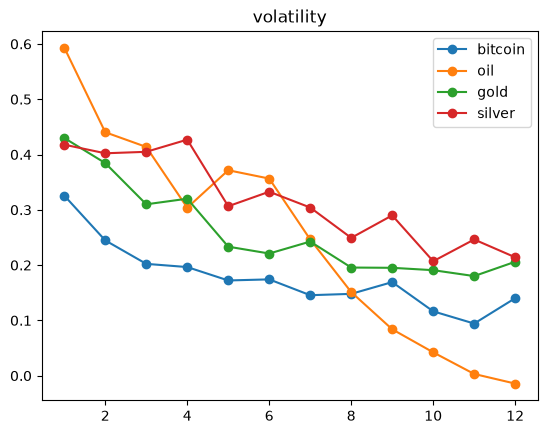

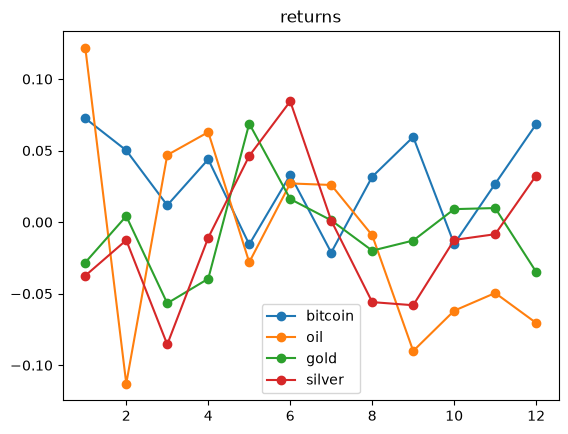

In [22]:
lags = range(1, 13)
weekly_ret = returns.resample("W-FRI").sum()

pd.DataFrame({c: [rv[c].autocorr(k) for k in lags] for c in rv}, index=lags).plot(marker="o", title="volatility")
pd.DataFrame({c: [weekly_ret[c].autocorr(k) for k in lags] for c in rv}, index=lags).plot(marker="o", title="returns")
plt.show()

In [23]:
print(rv.index[0], rv.index[-1])

2015-01-09 00:00:00 2026-10-02 00:00:00


In [24]:
rv.loc["2015":"2019", "gold"].autocorr(1)

np.float64(0.11750690001688652)

In [25]:
test = rv.loc["2021":]
naive = rv.shift(1).loc["2021":]
np.sqrt(((test - naive)**2).mean())

bitcoin    0.359099
oil        0.192272
gold       0.100997
silver     0.260698
dtype: float64

In [26]:
returns.to_csv("returns.csv")
rv.to_csv("rv.csv")